# Breast Cancer Diagnosis: Feature Selection & Model Evaluation

**Key Elements for Reproducibility:**
1. **Global Seed Control**: Fixed random state (`SEED = 42`) across data splits, cross-validation, and estimators.
2. **Preventing Data Leakage**: Data split into `X_train` and `X_test` before preprocessing; scaling is fitted strictly on `X_train`.
3. **Train-Test Evaluation**: Feature selection algorithms (Forward/Backward) are run on `X_train`, and candidate models are evaluated on the held-out `X_test` dataset.


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from google.colab import drive

import statsmodels.api as sm
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV, LinearRegression, RidgeClassifier, Ridge
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    log_loss, classification_report, confusion_matrix, roc_curve
)

warnings.filterwarnings('ignore')

# Global seed for complete reproducibility
SEED = 42
np.random.seed(SEED)

drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


# Data Cleaning and Train-Test Split

We load the dataset, clean extraneous columns (`Unnamed: 32`, `id`), and map `diagnosis` into binary integer target format ($M = 1, B = 0$). To guarantee reproducibility and prevent data leakage, we perform a stratified train-test split before applying feature scaling.

In [18]:
# Load dataset
df = pd.read_csv('gdrive/My Drive/Colab Notebooks/bern 02 stuff/Challenge project/data.csv')

# Drop unused columns
df = df.drop(columns=['Unnamed: 32', 'id'], errors='ignore')

# Convert target to binary (1 = Malignant, 0 = Benign)
df['diagnosis'] = df['diagnosis'].apply(lambda x: 1 if x == 'M' else 0)

X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print(f"Training Set Shape: {X_train.shape}")
print(f"Testing Set Shape:  {X_test.shape}")

Training Set Shape: (455, 30)
Testing Set Shape:  (114, 30)


# Feature Preprocessing & Scaling

We set up a `ColumnTransformer` to standardize numerical variables. The scaler is fitted only on the training set (`X_train`) and then applied to transform both `X_train` and `X_test`.

In [19]:
categorical_cols = X_train.select_dtypes(include=['object']).columns
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ]
)

# Fit on Train, transform Train and Test independently
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
df_X_train = pd.DataFrame(X_train_prep, columns=feature_names)
df_X_test = pd.DataFrame(X_test_prep, columns=feature_names)

# Forward and Backward Selection

We set up 10-fold cross-validation and compute Mallows' $C_p$, AIC, BIC, Adjusted $R^2$, and CV MSE using the training dataset (`df_X_train`, `y_train`).

In [20]:
# 10-Fold CV with fixed seed
cv = KFold(n_splits=10, shuffle=True, random_state=SEED)

# Full OLS Model on Training Data for Mallows' Cp calculation
full_mod = sm.OLS(y_train.values, sm.add_constant(df_X_train).values).fit()
sigma2_full = full_mod.mse_resid
n_train, p_total = df_X_train.shape

In [21]:
# Forward Selection Function (Trained exclusively on X_train)
def run_forward_selection(df_X, y, cv, sigma2_full):
    n, p = df_X.shape
    remaining = list(df_X.columns)
    selected = []
    records = []

    for k in range(1, p + 1):
        best_rss = np.inf
        best_feat = None

        for feat in remaining:
            X_curr = sm.add_constant(df_X[selected + [feat]])
            model = sm.OLS(y.values, X_curr.values).fit()
            if model.ssr < best_rss:
                best_rss = model.ssr
                best_feat = feat

        selected.append(best_feat)
        remaining.remove(best_feat)

        # Fit model at step k
        X_best = sm.add_constant(df_X[selected])
        ols_fit = sm.OLS(y.values, X_best.values).fit()

        # 10-Fold CV MSE
        scores = cross_val_score(
            LinearRegression(), df_X[selected], y,
            scoring='neg_mean_squared_error', cv=cv
        )
        cv_mse = -scores.mean()

        records.append({
            'k': k,
            'added_removed': f"+ {best_feat.split('__')[-1]}",
            'selected_features': list(selected),
            'RSS': ols_fit.ssr,
            'R2_adj': ols_fit.rsquared_adj,
            'AIC': ols_fit.aic,
            'BIC': ols_fit.bic,
            'Cp': (ols_fit.ssr / sigma2_full) - n + 2 * (k + 1),
            'CV_MSE': cv_mse
        })

    return pd.DataFrame(records)

In [22]:
# Backward Selection Function (Trained exclusively on X_train)
def run_backward_selection(df_X, y, cv, sigma2_full):
    n, p = df_X.shape
    current = list(df_X.columns)
    records = []

    # Record Full Model (k = p)
    X_full = sm.add_constant(df_X[current])
    ols_fit = sm.OLS(y.values, X_full.values).fit()
    scores = cross_val_score(
        LinearRegression(), df_X[current], y,
        scoring='neg_mean_squared_error', cv=cv
    )
    records.append({
        'k': p,
        'added_removed': 'Full Model',
        'selected_features': list(current),
        'RSS': ols_fit.ssr,
        'R2_adj': ols_fit.rsquared_adj,
        'AIC': ols_fit.aic,
        'BIC': ols_fit.bic,
        'Cp': (ols_fit.ssr / sigma2_full) - n + 2 * (p + 1),
        'CV_MSE': -scores.mean()
    })

    # Sequential Elimination
    for k in range(p - 1, 0, -1):
        best_rss = np.inf
        worst_feat = None

        for feat in current:
            sub_feats = [f for f in current if f != feat]
            X_curr = sm.add_constant(df_X[sub_feats])
            model = sm.OLS(y.values, X_curr.values).fit()
            if model.ssr < best_rss:
                best_rss = model.ssr
                worst_feat = feat

        current.remove(worst_feat)

        X_best = sm.add_constant(df_X[current])
        ols_fit = sm.OLS(y.values, X_best.values).fit()
        scores = cross_val_score(
            LinearRegression(), df_X[current], y,
            scoring='neg_mean_squared_error', cv=cv
        )

        records.append({
            'k': k,
            'added_removed': f"- {worst_feat.split('__')[-1]}",
            'selected_features': list(current),
            'RSS': ols_fit.ssr,
            'R2_adj': ols_fit.rsquared_adj,
            'AIC': ols_fit.aic,
            'BIC': ols_fit.bic,
            'Cp': (ols_fit.ssr / sigma2_full) - n + 2 * (k + 1),
            'CV_MSE': -scores.mean()
        })

    return pd.DataFrame(records).sort_values('k').reset_index(drop=True)

In [23]:
# Run selections on training data
df_fw = run_forward_selection(df_X_train, y_train, cv, sigma2_full)
df_bw = run_backward_selection(df_X_train, y_train, cv, sigma2_full)

print("\n--- FORWARD SELECTION SUMMARY (TRAIN) ---")
print(df_fw[['k', 'added_removed', 'RSS', 'R2_adj', 'AIC', 'BIC', 'Cp', 'CV_MSE']].head(15))

print("\n--- BACKWARD SELECTION SUMMARY (TRAIN) ---")
print(df_bw[['k', 'added_removed', 'RSS', 'R2_adj', 'AIC', 'BIC', 'Cp', 'CV_MSE']].head(15))

print("\nOptimal Features (k):")
print("Forward Min CV MSE k:", df_fw.loc[df_fw['CV_MSE'].idxmin(), 'k'])
print("Backward Min CV MSE k:", df_bw.loc[df_bw['CV_MSE'].idxmin(), 'k'])
print("Forward Min AIC k:", df_fw.loc[df_fw['AIC'].idxmin(), 'k'])
print("Backward Min AIC k:", df_bw.loc[df_bw['AIC'].idxmin(), 'k'])
print("Forward Min BIC k:", df_fw.loc[df_fw['BIC'].idxmin(), 'k'])
print("Backward Min BIC k:", df_bw.loc[df_bw['BIC'].idxmin(), 'k'])


--- FORWARD SELECTION SUMMARY (TRAIN) ---
     k              added_removed        RSS    R2_adj         AIC  \
0    1     + concave points_worst  40.647189  0.617435  196.241748   
1    2             + radius_worst  33.613268  0.682937  111.787737   
2    3            + texture_worst  30.809473  0.708740   74.157850   
3    4               + area_worst  29.638956  0.719183   58.534499   
4    5         + smoothness_worst  28.293405  0.731334   39.394812   
5    6                + radius_se  27.298122  0.740207   25.100891   
6    7           + symmetry_worst  26.760597  0.744752   18.052130   
7    8         + compactness_mean  26.309097  0.748496   12.309960   
8    9      + concave points_mean  25.754931  0.753241    4.623614   
9   10  + fractal_dimension_worst  24.987730  0.760052   -7.136131   
10  11            + smoothness_se  24.834325  0.760987   -7.938084   
11  12     + fractal_dimension_se  24.526477  0.763415  -11.613542   
12  13        + concave points_se  24.342206  0

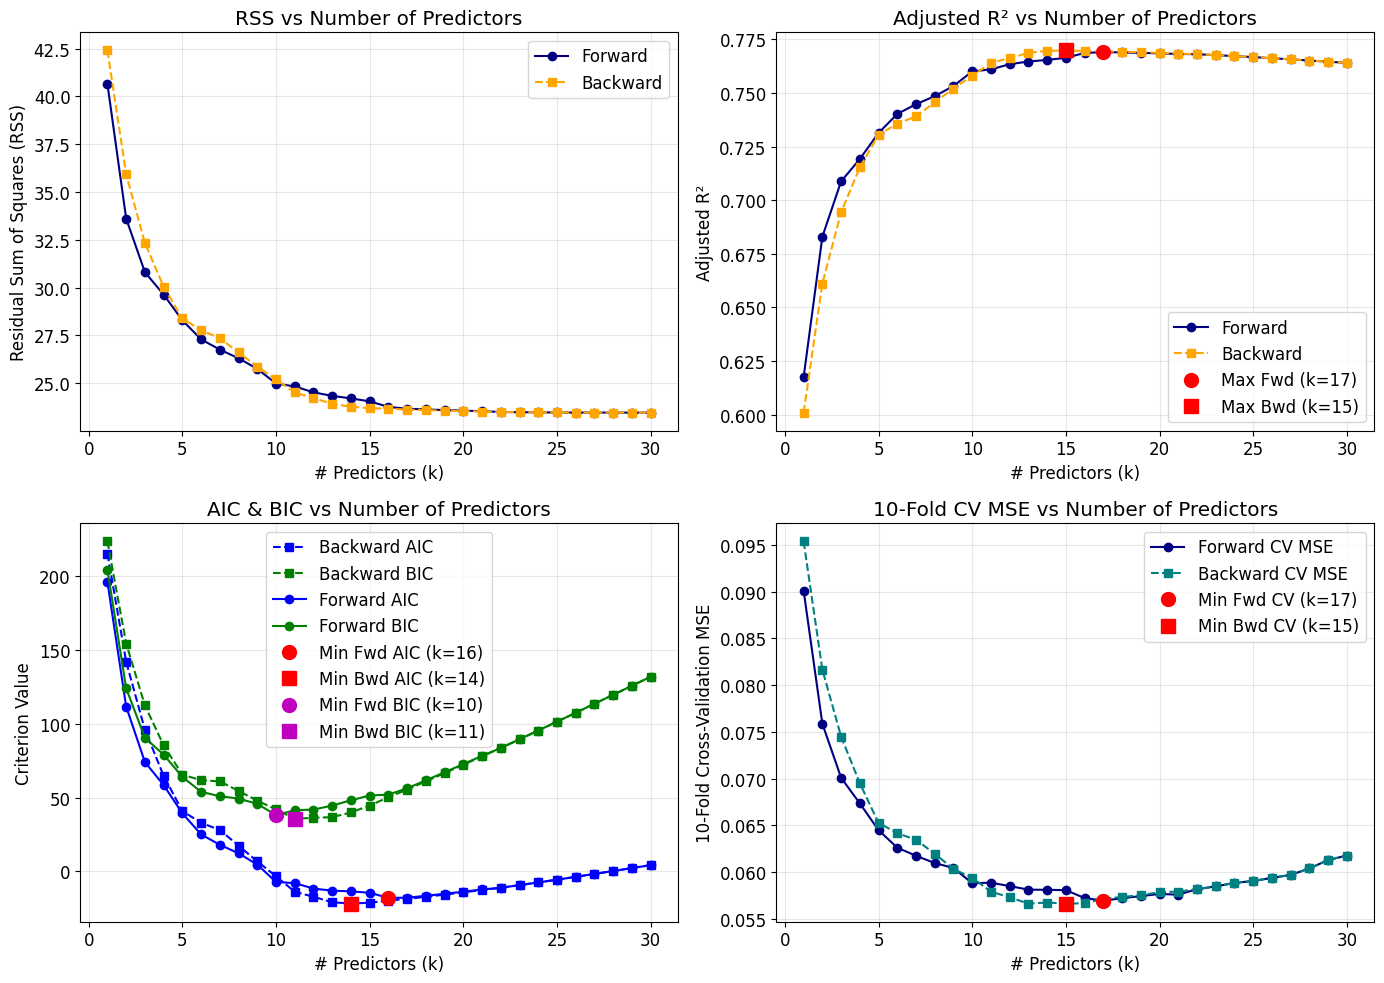

In [24]:
# Plotting Comparison Grid
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plt.rcParams.update({'font.size': 12})

# RSS
axes[0, 0].plot(df_fw['k'], df_fw['RSS'], marker='o', linestyle='-', label='Forward', color='navy')
axes[0, 0].plot(df_bw['k'], df_bw['RSS'], marker='s', linestyle='--', label='Backward', color='orange')
axes[0, 0].set_xlabel('# Predictors (k)')
axes[0, 0].set_ylabel('Residual Sum of Squares (RSS)')
axes[0, 0].set_title('RSS vs Number of Predictors')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Adjusted R2
axes[0, 1].plot(df_fw['k'], df_fw['R2_adj'], marker='o', linestyle='-', label='Forward', color='navy')
axes[0, 1].plot(df_bw['k'], df_bw['R2_adj'], marker='s', linestyle='--', label='Backward', color='orange')
best_bw_r2 = df_bw.loc[df_bw['R2_adj'].idxmax()]
best_fw_r2 = df_fw.loc[df_fw['R2_adj'].idxmax()]
axes[0, 1].plot(best_fw_r2['k'], best_fw_r2['R2_adj'], 'ro', markersize=10, label=f'Max Fwd (k={best_fw_r2["k"]})')
axes[0, 1].plot(best_bw_r2['k'], best_bw_r2['R2_adj'], 'rs', markersize=10, label=f'Max Bwd (k={best_bw_r2["k"]})')
axes[0, 1].set_xlabel('# Predictors (k)')
axes[0, 1].set_ylabel('Adjusted R²')
axes[0, 1].set_title('Adjusted R² vs Number of Predictors')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# AIC & BIC (Forward + Backward)
axes[1, 0].plot(df_bw['k'], df_bw['AIC'], 'b--s', label='Backward AIC')
axes[1, 0].plot(df_bw['k'], df_bw['BIC'], 'g--s', label='Backward BIC')
axes[1, 0].plot(df_bw['k'], df_fw['AIC'], 'b-o', label='Forward AIC')
axes[1, 0].plot(df_bw['k'], df_fw['BIC'], 'g-o', label='Forward BIC')
best_bw_r2 = df_bw.loc[df_bw['AIC'].idxmin()]
best_fw_r2 = df_fw.loc[df_fw['AIC'].idxmin()]
axes[1, 0].plot(best_fw_r2['k'], best_fw_r2['AIC'], 'ro', markersize=10, label=f'Min Fwd AIC (k={best_fw_r2["k"]})')
axes[1, 0].plot(best_bw_r2['k'], best_bw_r2['AIC'], 'rs', markersize=10, label=f'Min Bwd AIC (k={best_bw_r2["k"]})')


best_bw_r2 = df_bw.loc[df_bw['BIC'].idxmin()]
best_fw_r2 = df_fw.loc[df_fw['BIC'].idxmin()]
axes[1, 0].plot(best_fw_r2['k'], best_fw_r2['BIC'], 'mo', markersize=10, label=f'Min Fwd BIC (k={best_fw_r2["k"]})')
axes[1, 0].plot(best_bw_r2['k'], best_bw_r2['BIC'], 'ms', markersize=10, label=f'Min Bwd BIC (k={best_bw_r2["k"]})')



axes[1, 0].set_xlabel('# Predictors (k)')
axes[1, 0].set_ylabel('Criterion Value')
axes[1, 0].set_title('AIC & BIC vs Number of Predictors')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# CV MSE Comparison
axes[1, 1].plot(df_fw['k'], df_fw['CV_MSE'], marker='o', linestyle='-', label='Forward CV MSE', color='navy')
axes[1, 1].plot(df_bw['k'], df_bw['CV_MSE'], marker='s', linestyle='--', label='Backward CV MSE', color='teal')
best_fw_cv = df_fw.loc[df_fw['CV_MSE'].idxmin()]
best_bw_cv = df_bw.loc[df_bw['CV_MSE'].idxmin()]
axes[1, 1].plot(best_fw_cv['k'], best_fw_cv['CV_MSE'], 'ro', markersize=10, label=f'Min Fwd CV (k={best_fw_cv["k"]})')
axes[1, 1].plot(best_bw_cv['k'], best_bw_cv['CV_MSE'], 'rs', markersize=10, label=f'Min Bwd CV (k={best_bw_cv["k"]})')
axes[1, 1].set_xlabel('# Predictors (k)')
axes[1, 1].set_ylabel('10-Fold Cross-Validation MSE')
axes[1, 1].set_title('10-Fold CV MSE vs Number of Predictors')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Lasso and Ridge Regression

In [ ]:
# Lasso (L1 Regularization - Feature Selection)
lasso_cv = LogisticRegressionCV(
    penalty='l1',
    solver='liblinear',
    Cs=np.logspace(-2, 2, 100),
    cv=cv,
    scoring='neg_log_loss',
    random_state=SEED,
    max_iter=2000
)
lasso_cv.fit(df_X_train, y_train)

# Lasso Feature Selection (Non-zero coefficients)
non_zero_lasso = list(df_X_train.columns[lasso_cv.coef_[0] != 0])

In [ ]:
# Ridge (L2 Regularization - Weight Shrinkage)
ridge_cv = LogisticRegressionCV(
    penalty='l2',
    solver='lbfgs',
    Cs=np.logspace(-2, 2, 100),
    cv=cv,
    scoring='neg_log_loss',
    random_state=SEED,
    max_iter=2000
)
ridge_cv.fit(df_X_train, y_train)

In [32]:
# Coefficient DataFrame
df_coefs = pd.DataFrame({
    'Feature': df_X_train.columns,
    'Lasso_Coef': lasso_cv.coef_[0],
    'Ridge_Coef': ridge_cv.coef_[0]
}).sort_values(by='Ridge_Coef', key=abs, ascending=False)

# Selected Regularization Parameters (C = 1 / lambda)
best_c_lasso = lasso_cv.C_[0]
best_c_ridge = ridge_cv.C_[0]

print(f"Optimal C (Lasso): {best_c_lasso:.4f}")
print(f"Optimal C (Ridge): {best_c_ridge:.4f}")
print(f"Lasso selected {len(non_zero_lasso)} / {df_X_train.shape[1]} features.")

Optimal C (Lasso): 1.0476
Optimal C (Ridge): 0.7925
Lasso selected 14 / 30 features.


# Final Model Training and Test Set Evaluation

We extract the selected feature subsets for four candidate models and train **Logistic Regression** and **Linear Regression (OLS)** classifiers on `df_X_train`. We then evaluate their performance on the held-out test set (`df_X_test`).

In [39]:
# Identify optimal feature sets from selection summaries
best_fw_k = int(df_fw.loc[df_fw['AIC'].idxmin(), 'k'])
best_fw_feats = df_fw.loc[df_fw['k'] == best_fw_k, 'selected_features'].values[0]

best_bw_k = int(df_bw.loc[df_bw['AIC'].idxmin(), 'k'])
best_bw_feats = df_bw.loc[df_bw['k'] == best_bw_k, 'selected_features'].values[0]

bic_k_fw = int(df_fw.loc[df_fw['BIC'].idxmin(), 'k'])
bic_feats_fw = df_fw.loc[df_fw['k'] == bic_k_fw, 'selected_features'].values[0]

bic_k_bw = int(df_bw.loc[df_bw['BIC'].idxmin(), 'k'])
bic_feats_bw = df_bw.loc[df_bw['k'] == bic_k_bw, 'selected_features'].values[0]

full_feats = list(df_X_train.columns)

# 1. Ridge (L2) Feature Selection (extract features with non-zero weights)
ridge_selector = RidgeClassifier(alpha=1.0, random_state=SEED)
ridge_selector.fit(df_X_train, y_train)
non_zero_ridge = list(df_X_train.columns[ridge_selector.coef_.ravel() != 0])

# Map feature sets to evaluation dictionary
models_to_evaluate = {
    f"Forward Selected (lowest AIC) (k={best_fw_k})": best_fw_feats,
    f"Backward Selected (lowest AIC) (k={best_bw_k})": best_bw_feats,
    f"Forward Selected (lowest BIC) (k={bic_k_fw})": bic_feats_fw,
    f"Backward Selected (lowest BIC) (k={bic_k_bw})": bic_feats_bw,
    f"Lasso L1 Selected Features (k={len(non_zero_lasso)})": non_zero_lasso,
    f"Ridge L2 Selected Features (k={len(non_zero_ridge)})": non_zero_ridge,
}

test_results = []

for model_name, feats in models_to_evaluate.items():
    # 1. Logistic Regression Classifier
    clf = LogisticRegression(random_state=SEED, max_iter=1000)
    clf.fit(df_X_train[feats], y_train)

    y_pred_train = clf.predict(df_X_train[feats])
    y_pred_test = clf.predict(df_X_test[feats])
    y_prob_test = clf.predict_proba(df_X_test[feats])[:, 1]

    # 2. Linear Regression (OLS) for Test MSE reference
    ols = LinearRegression()
    ols.fit(df_X_train[feats], y_train)
    ols_test_pred = ols.predict(df_X_test[feats])
    test_ols_mse = mean_squared_error(y_test, ols_test_pred)

    # 3. Ridge Regression for Test MSE reference
    ridge_reg = Ridge(alpha=1.0, random_state=SEED)
    ridge_reg.fit(df_X_train[feats], y_train)
    ridge_test_pred = ridge_reg.predict(df_X_test[feats])
    test_ridge_mse = mean_squared_error(y_test, ridge_test_pred)

    test_results.append({
        'Model Architecture': model_name,
        '# Features': len(feats),
        'Train Accuracy': accuracy_score(y_train, y_pred_train),
        'Test Accuracy': accuracy_score(y_test, y_pred_test),
        'Test Precision': precision_score(y_test, y_pred_test),
        'Test Recall': recall_score(y_test, y_pred_test),
        'Test F1 Score': f1_score(y_test, y_pred_test),
        'Test ROC-AUC': roc_auc_score(y_test, y_prob_test),
        'Test Linear MSE': test_ols_mse,
        'Test Ridge MSE': test_ridge_mse
    })

df_results = pd.DataFrame(test_results)
print("\n=================== HELD-OUT TEST SET EVALUATION ===================")
print(df_results.to_string(index=False))

# Detailed Classification Report for Best Forward Logistic Model
best_clf = LogisticRegression(random_state=SEED, max_iter=1000)
best_clf.fit(df_X_train[best_fw_feats], y_train)
best_y_pred = best_clf.predict(df_X_test[best_fw_feats])

print(f"\n--- Classification Report: Forward Selected Model (k={best_fw_k}) ---")
print(classification_report(y_test, best_y_pred, target_names=['Benign (0)', 'Malignant (1)']))


=================== HELD-OUT TEST SET EVALUATION ===================
                   Model Architecture  # Features  Train Accuracy  Test Accuracy  Test Precision  Test Recall  Test F1 Score  Test ROC-AUC  Test Linear MSE  Test Ridge MSE
 Forward Selected (lowest AIC) (k=16)          16        0.982418       0.982456         1.00000     0.952381       0.975610      0.996032         0.061011        0.060550
Backward Selected (lowest AIC) (k=14)          14        0.984615       0.973684         1.00000     0.928571       0.962963      0.994709         0.060383        0.061031
 Forward Selected (lowest BIC) (k=10)          10        0.982418       0.973684         0.97561     0.952381       0.963855      0.997024         0.062794        0.062170
Backward Selected (lowest BIC) (k=11)          11        0.975824       0.973684         1.00000     0.928571       0.962963      0.993717         0.058461        0.058780
    Lasso L1 Selected Features (k=14)          14        0.989011     